In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv('/content/drive/MyDrive/kc_house_data.csv')

In [2]:
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [3]:
df.shape

(21613, 21)

In [4]:
df.columns

Index(['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
       'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
       'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode',
       'lat', 'long', 'sqft_living15', 'sqft_lot15'],
      dtype='object')

In [5]:
df['date'] = pd.to_datetime(df['date'], errors='coerce')

if 'sale_year' not in df.columns:
    df['sale_year'] = df['date'].dt.year

if 'property_age' not in df.columns:
    df['property_age'] = df['sale_year'] - df['yr_built']

if 'is_renovated' not in df.columns:
    df['is_renovated'] = np.where(
        df['yr_renovated'] > 0,
        'Renovated',
        'Not Renovated'
    )

if 'price_per_sqft_living' not in df.columns:
    df['price_per_sqft_living'] = (
        df['price'] / df['sqft_living'].replace(0, np.nan)
    )

if 'price_per_sqft_lot' not in df.columns:
    df['price_per_sqft_lot'] = (
        df['price'] / df['sqft_lot'].replace(0, np.nan)
    )

df = df.dropna(
    subset=['price', 'sqft_living', 'lat', 'long']
)

print(df[
    [
        'price',
        'sqft_living',
        'sale_year',
        'property_age',
        'is_renovated',
        'price_per_sqft_living',
        'price_per_sqft_lot'
    ]
].head())

      price  sqft_living  sale_year  property_age   is_renovated  \
0  221900.0         1180       2014            59  Not Renovated   
1  538000.0         2570       2014            63      Renovated   
2  180000.0          770       2015            82  Not Renovated   
3  604000.0         1960       2014            49  Not Renovated   
4  510000.0         1680       2015            28  Not Renovated   

   price_per_sqft_living  price_per_sqft_lot  
0             188.050847           39.274336  
1             209.338521           74.288870  
2             233.766234           18.000000  
3             308.163265          120.800000  
4             303.571429           63.118812  


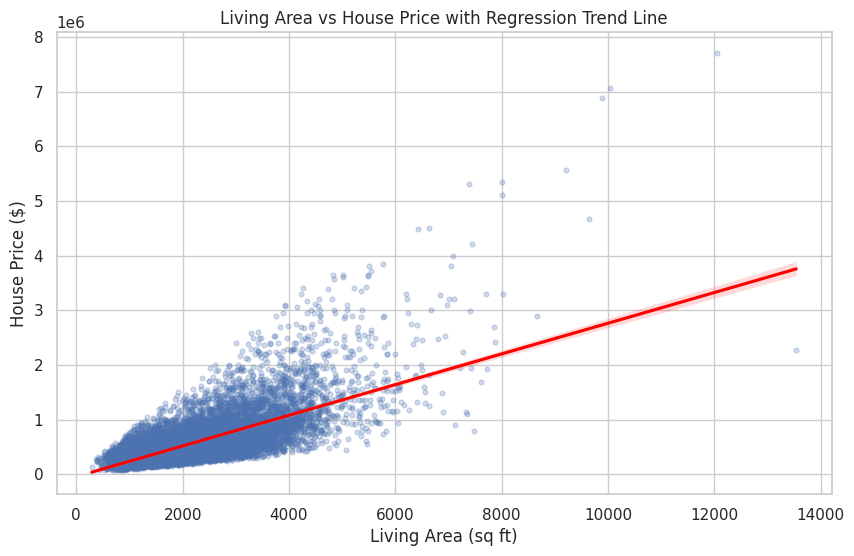

In [6]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x='sqft_living',
    y='price',
    scatter_kws={'alpha': 0.25, 's': 12},
    line_kws={'color': 'red'}
)

plt.title('Living Area vs House Price with Regression Trend Line')
plt.xlabel('Living Area (sq ft)')
plt.ylabel('House Price ($)')
plt.show()

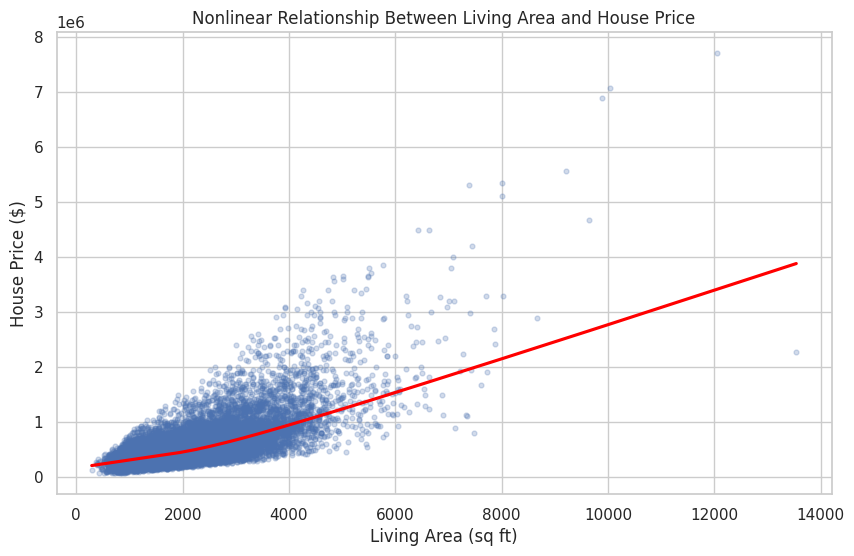

In [8]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x='sqft_living',
    y='price',
    lowess=True,
    scatter_kws={'alpha': 0.25, 's': 12},
    line_kws={'color': 'red'}
)

plt.title('Nonlinear Relationship Between Living Area and House Price')
plt.xlabel('Living Area (sq ft)')
plt.ylabel('House Price ($)')
plt.show()

In [9]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

X = df[['sqft_living']]
y = df['price']

model.fit(X, y)

df['predicted_price'] = model.predict(X)
df['price_difference'] = df['price'] - df['predicted_price']

high_value = df.sort_values(
    'price_difference',
    ascending=False
).head(10)

low_value = df.sort_values(
    'price_difference'
).head(10)

print("10 HOUSES PRICED HIGHEST ABOVE THE LINEAR TREND")

print(high_value[
    [
        'id', 'price', 'sqft_living',
        'grade', 'waterfront', 'zipcode',
        'price_difference'
    ]
])

print("\n10 HOUSES PRICED LOWEST BELOW THE LINEAR TREND")

print(low_value[
    [
        'id', 'price', 'sqft_living',
        'grade', 'waterfront', 'zipcode',
        'price_difference'
    ]
])

10 HOUSES PRICED HIGHEST ABOVE THE LINEAR TREND
               id      price  sqft_living  grade  waterfront  zipcode  \
7252   6762700020  7700000.0        12050     13           0    98102   
3914   9808700762  7062500.0        10040     11           1    98004   
9254   9208900037  6885000.0         9890     13           0    98039   
1315   7558700030  5300000.0         7390     12           1    98040   
1448   8907500070  5350000.0         8000     12           0    98004   
4411   2470100110  5570000.0         9200     13           0    98039   
1164   1247600105  5110800.0         8010     12           1    98033   
8638   3835500195  4489000.0         6430     12           0    98004   
2626   7738500731  4500000.0         6640     12           1    98155   
15255  2425049063  3640900.0         4830     11           1    98039   

       price_difference  
7252       4.362067e+06  
3914       4.288620e+06  
9254       4.153214e+06  
1315       3.269773e+06  
1448       3.14859

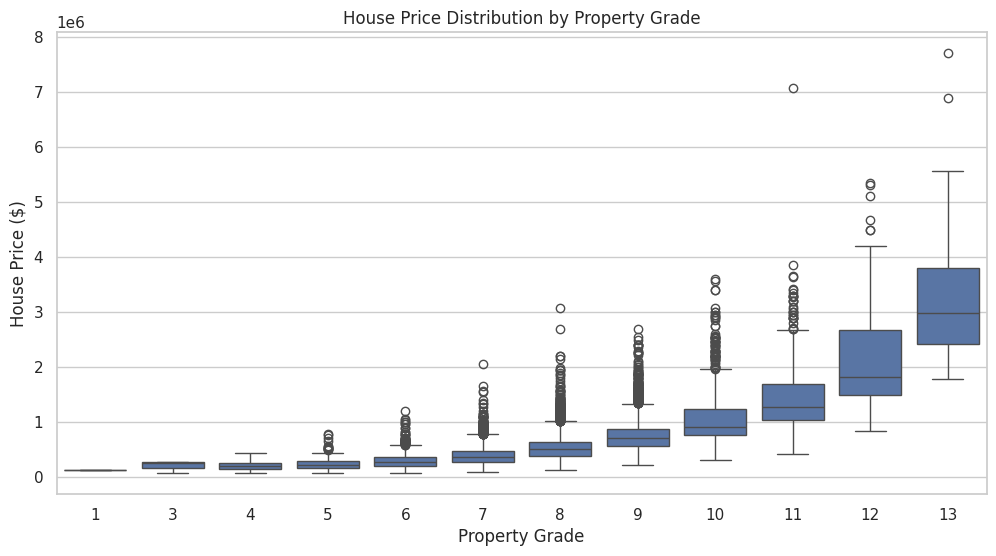

In [10]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='grade',
    y='price'
)

plt.title('House Price Distribution by Property Grade')
plt.xlabel('Property Grade')
plt.ylabel('House Price ($)')
plt.show()


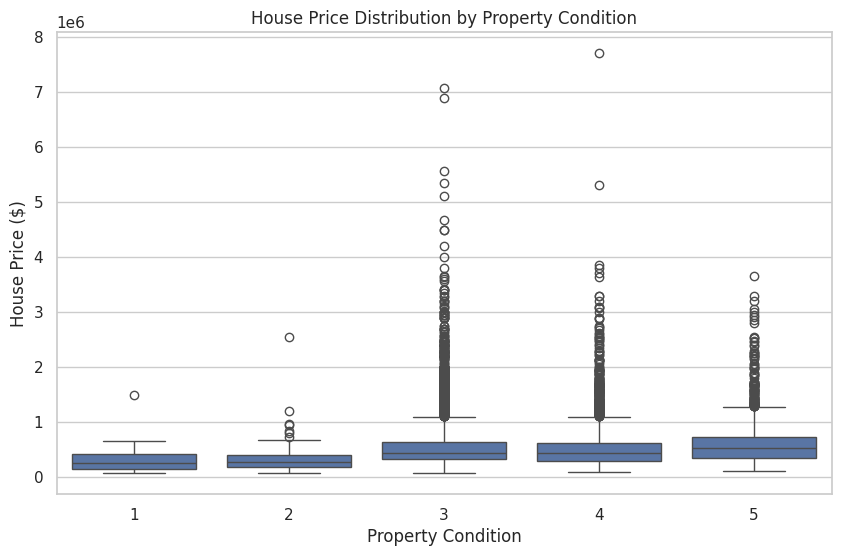

In [11]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='condition',
    y='price'
)

plt.title('House Price Distribution by Property Condition')
plt.xlabel('Property Condition')
plt.ylabel('House Price ($)')
plt.show()

MEDIAN HOUSE PRICE BY PROPERTY GRADE
grade
13    2983000.0
12    1817500.0
11    1284000.0
10     914327.0
9      720000.0
8      510000.0
7      375000.0
6      275276.5
3      262000.0
5      228700.0
4      205000.0
1      142000.0
Name: price, dtype: float64


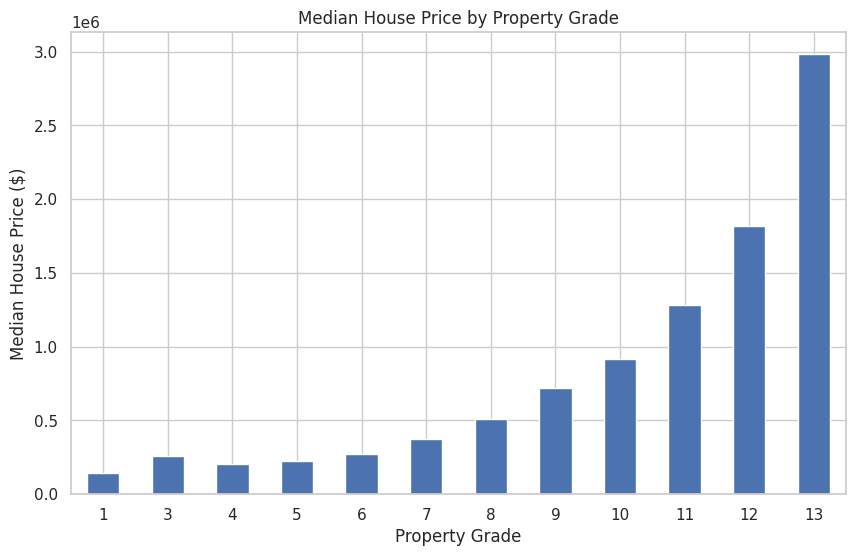

In [12]:
grade_median_prices = df.groupby('grade')['price'].median()

print("MEDIAN HOUSE PRICE BY PROPERTY GRADE")
print(grade_median_prices.sort_values(ascending=False))

grade_median_prices.sort_index().plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Median House Price by Property Grade')
plt.xlabel('Property Grade')
plt.ylabel('Median House Price ($)')
plt.xticks(rotation=0)
plt.show()

MEDIAN HOUSE PRICE BY PROPERTY CONDITION
condition
5    526000.0
3    450000.0
4    440000.0
2    279000.0
1    262500.0
Name: price, dtype: float64


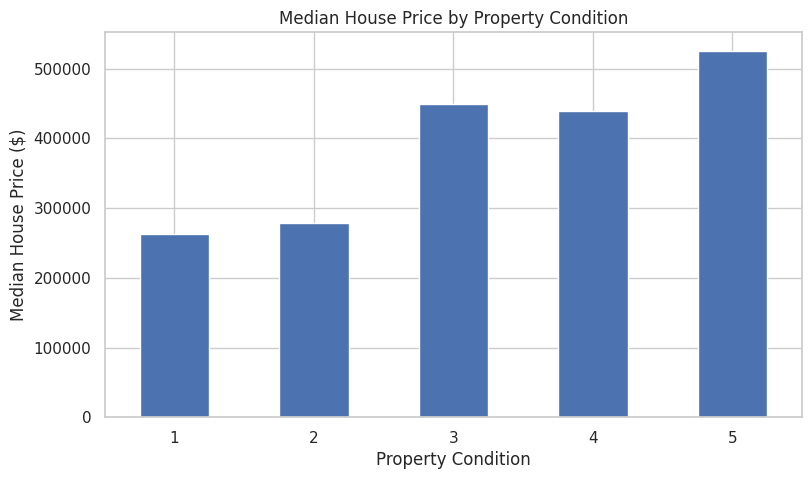

In [13]:
condition_median_prices = df.groupby('condition')['price'].median()

print("MEDIAN HOUSE PRICE BY PROPERTY CONDITION")
print(condition_median_prices.sort_values(ascending=False))

condition_median_prices.sort_index().plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Median House Price by Property Condition')
plt.xlabel('Property Condition')
plt.ylabel('Median House Price ($)')
plt.xticks(rotation=0)
plt.show()

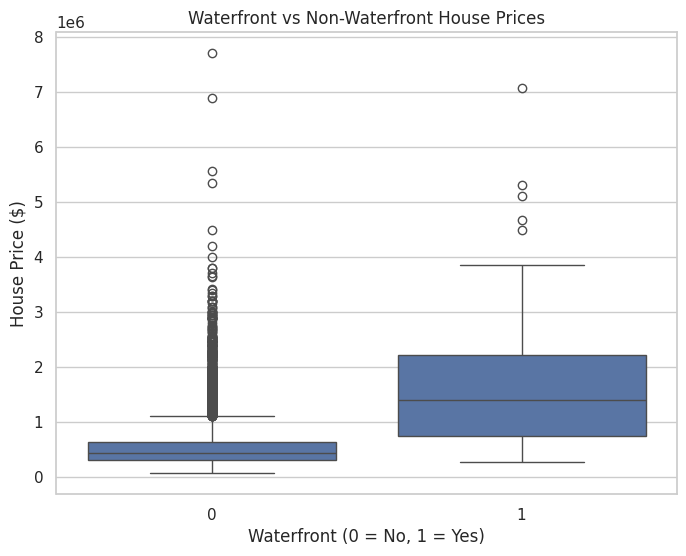

In [14]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x='waterfront',
    y='price'
)

plt.title('Waterfront vs Non-Waterfront House Prices')
plt.xlabel('Waterfront (0 = No, 1 = Yes)')
plt.ylabel('House Price ($)')
plt.show()

In [15]:
waterfront_prices = df.groupby('waterfront')['price'].agg(
    ['mean', 'median', 'count']
)

print("WATERFRONT PRICE ANALYSIS")
print(waterfront_prices)

if 0 in waterfront_prices.index and 1 in waterfront_prices.index:
    no_waterfront = waterfront_prices.loc[0, 'mean']
    with_waterfront = waterfront_prices.loc[1, 'mean']

    premium = (
        (with_waterfront - no_waterfront) / no_waterfront
    ) * 100

    print(
        "OBSERVED AVERAGE PRICE DIFFERENCE: $",
        round(with_waterfront - no_waterfront, 2)
    )

    print(
        "OBSERVED WATERFRONT PRICE PREMIUM:",
        round(premium, 2),
        "%"
    )

WATERFRONT PRICE ANALYSIS
                    mean     median  count
waterfront                                
0           5.315636e+05   450000.0  21450
1           1.661876e+06  1400000.0    163
OBSERVED AVERAGE PRICE DIFFERENCE: $ 1130312.42
OBSERVED WATERFRONT PRICE PREMIUM: 212.64 %


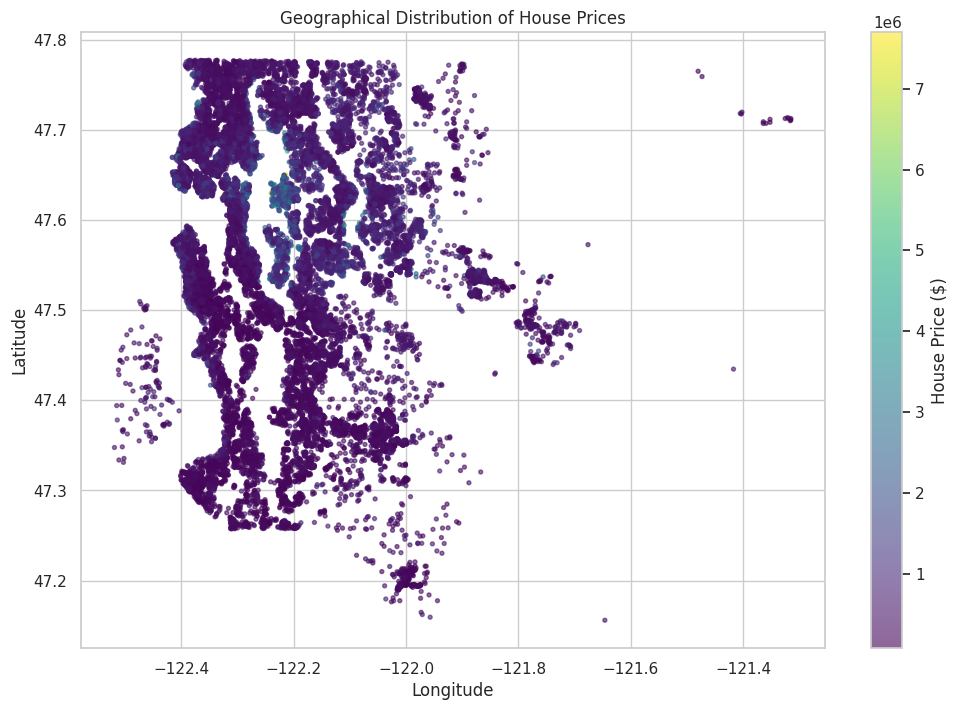

In [16]:
plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    df['long'],
    df['lat'],
    c=df['price'],
    cmap='viridis',
    s=8,
    alpha=0.6
)

plt.colorbar(scatter, label='House Price ($)')

plt.title('Geographical Distribution of House Prices')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

TOP 10 ZIP CODES BY MEDIAN HOUSE PRICE
         median_price  average_price  number_of_houses  average_grade  \
zipcode                                                                 
98039       1892500.0   2.160607e+06                50       9.560000   
98004       1150000.0   1.355927e+06               317       8.687697   
98040        993750.0   1.194230e+06               282       8.960993   
98112        915000.0   1.095499e+06               269       8.442379   
98005        765475.0   8.101649e+05               168       8.488095   
98006        760184.5   8.596848e+05               498       8.795181   
98119        744975.0   8.494480e+05               184       8.021739   
98075        739999.0   7.905767e+05               359       9.008357   
98109        736000.0   8.796236e+05               109       8.018349   
98102        720000.0   9.012583e+05               105       8.285714   

         average_living_area  
zipcode                       
98039            3800.

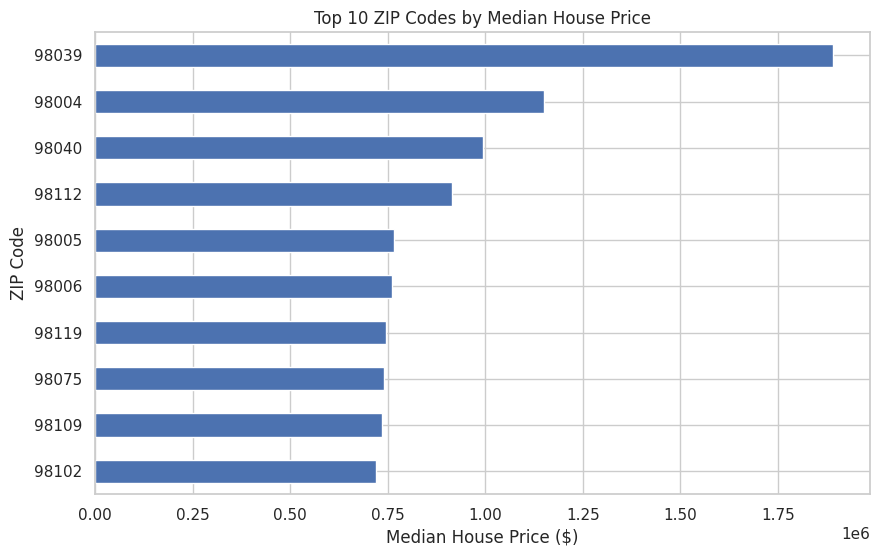

In [17]:
zipcode_prices = df.groupby('zipcode').agg(
    median_price=('price', 'median'),
    average_price=('price', 'mean'),
    number_of_houses=('price', 'count'),
    average_grade=('grade', 'mean'),
    average_living_area=('sqft_living', 'mean')
).sort_values(
    'median_price',
    ascending=False
)

print("TOP 10 ZIP CODES BY MEDIAN HOUSE PRICE")
print(zipcode_prices.head(10))

top_zips = zipcode_prices.head(10).sort_values('median_price')

plt.figure(figsize=(10, 6))

top_zips['median_price'].plot(kind='barh')

plt.title('Top 10 ZIP Codes by Median House Price')
plt.xlabel('Median House Price ($)')
plt.ylabel('ZIP Code')
plt.show()

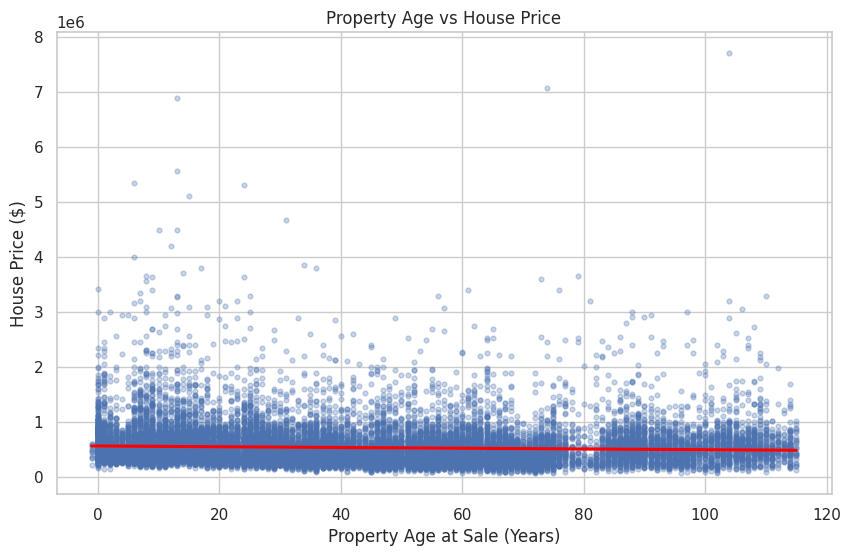

In [18]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x='property_age',
    y='price',
    scatter_kws={'alpha': 0.3, 's': 12},
    line_kws={'color': 'red'}
)

plt.title('Property Age vs House Price')
plt.xlabel('Property Age at Sale (Years)')
plt.ylabel('House Price ($)')
plt.show()

AVERAGE HOUSE PRICE BY RENOVATION STATUS
is_renovated
Not Renovated    530360.818155
Renovated        760379.029540
Name: price, dtype: float64


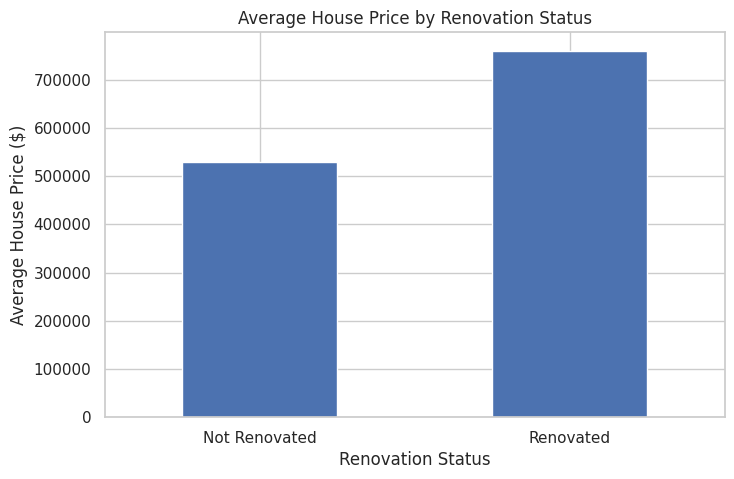

In [19]:
renovation_prices = df.groupby('is_renovated')['price'].mean()

print("AVERAGE HOUSE PRICE BY RENOVATION STATUS")
print(renovation_prices)

renovation_prices.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Average House Price by Renovation Status')
plt.xlabel('Renovation Status')
plt.ylabel('Average House Price ($)')
plt.xticks(rotation=0)
plt.show()

AVERAGE PRICE PER SQUARE FOOT BY PROPERTY GRADE
grade
1     489.655172
3     360.817706
4     362.381152
5     278.933609
6     270.991691
7     251.902028
8     258.086806
9     275.767174
10    307.589375
11    342.249732
12    401.853756
13    483.650379
Name: price_per_sqft_living, dtype: float64


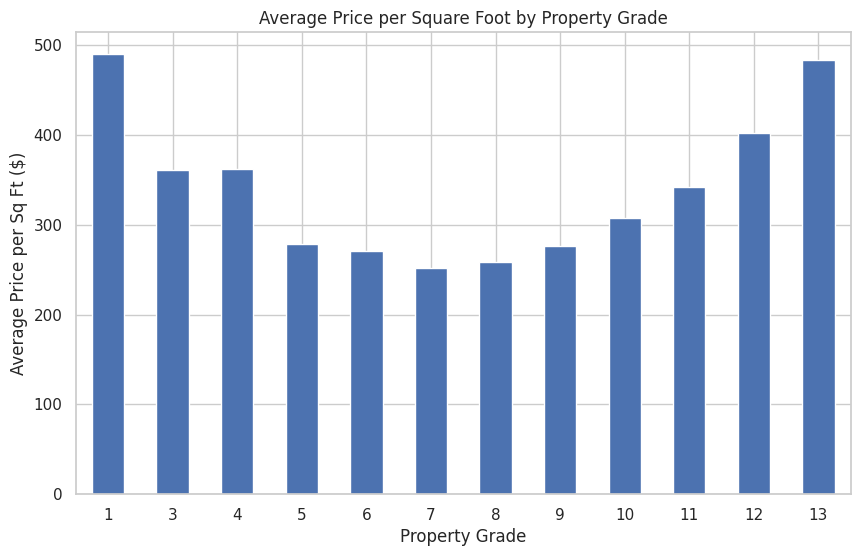

In [20]:
grade_prices = df.groupby('grade')['price_per_sqft_living'].mean()

print("AVERAGE PRICE PER SQUARE FOOT BY PROPERTY GRADE")
print(grade_prices)

grade_prices.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Average Price per Square Foot by Property Grade')
plt.xlabel('Property Grade')
plt.ylabel('Average Price per Sq Ft ($)')
plt.xticks(rotation=0)
plt.show()


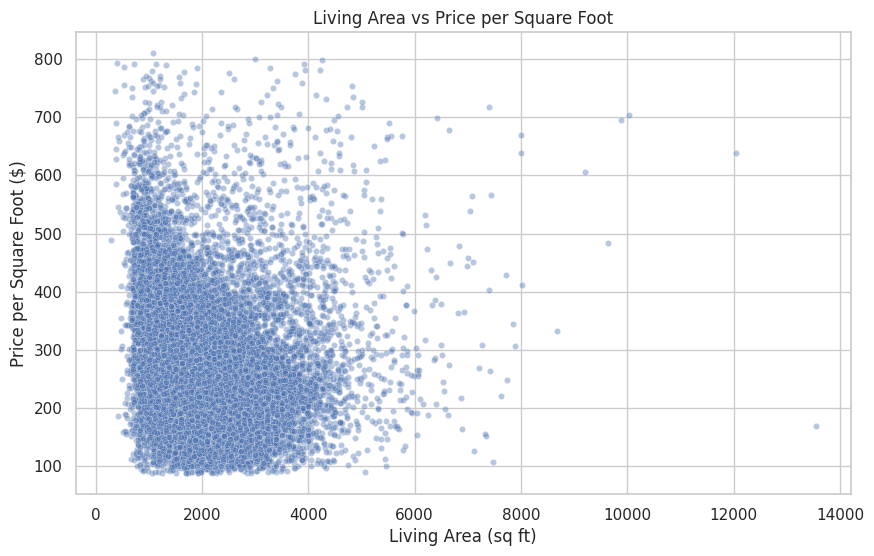

In [21]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='sqft_living',
    y='price_per_sqft_living',
    alpha=0.4,
    s=20
)

plt.title('Living Area vs Price per Square Foot')
plt.xlabel('Living Area (sq ft)')
plt.ylabel('Price per Square Foot ($)')
plt.show()


AVERAGE PRICE PER SQUARE FOOT BY PROPERTY CONDITION
condition
1    290.361552
2    244.625079
3    257.398188
4    270.877775
5    298.977801
Name: price_per_sqft_living, dtype: float64


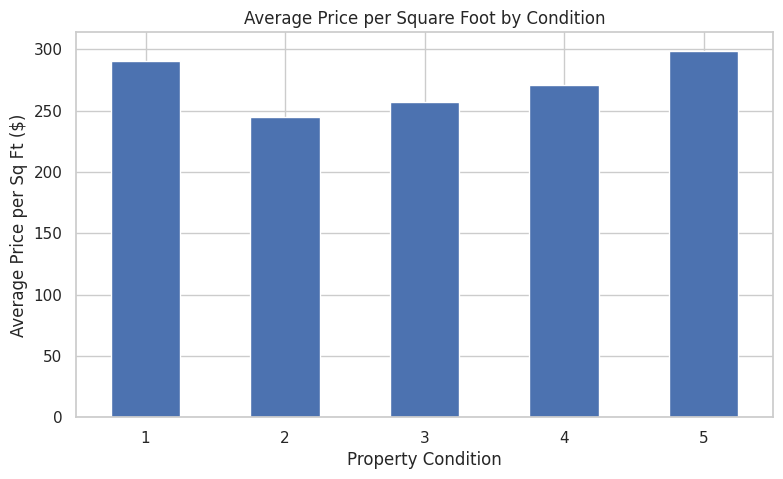

In [22]:
condition_prices = df.groupby('condition')['price_per_sqft_living'].mean()

print("AVERAGE PRICE PER SQUARE FOOT BY PROPERTY CONDITION")
print(condition_prices)

condition_prices.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Average Price per Square Foot by Condition')
plt.xlabel('Property Condition')
plt.ylabel('Average Price per Sq Ft ($)')
plt.xticks(rotation=0)
plt.show()

AVERAGE HOUSE PRICE BY NUMBER OF BEDROOMS
bedrooms
0     4.095038e+05
1     3.176429e+05
2     4.013727e+05
3     4.662321e+05
4     6.354195e+05
5     7.865998e+05
6     8.255206e+05
7     9.511847e+05
8     1.105077e+06
9     8.939998e+05
10    8.193333e+05
11    5.200000e+05
33    6.400000e+05
Name: price, dtype: float64


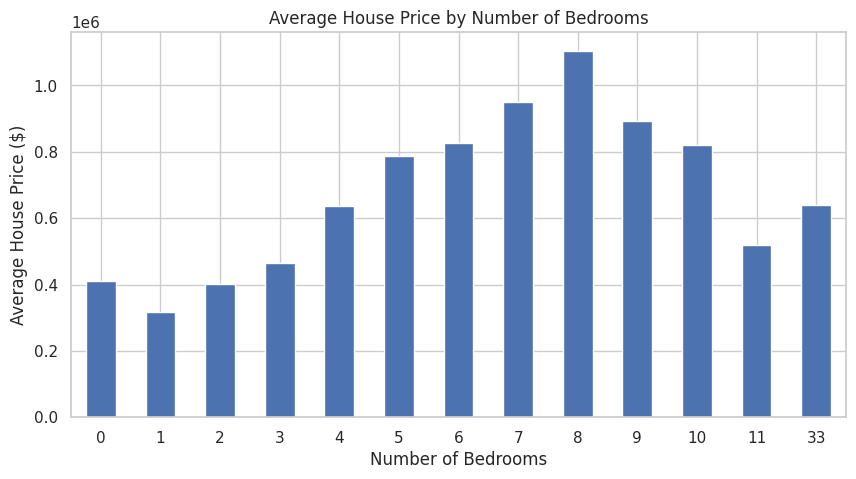

In [23]:
bedroom_prices = df.groupby('bedrooms')['price'].mean()

print("AVERAGE HOUSE PRICE BY NUMBER OF BEDROOMS")
print(bedroom_prices)

bedroom_prices.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Average House Price by Number of Bedrooms')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Average House Price ($)')
plt.xticks(rotation=0)
plt.show()

AVERAGE HOUSE PRICE BY NUMBER OF BATHROOMS
bathrooms
0.00    4.481600e+05
0.50    2.373750e+05
0.75    2.945209e+05
1.00    3.470412e+05
1.25    6.212167e+05
1.50    4.093222e+05
1.75    4.548961e+05
2.00    4.578897e+05
2.25    5.336768e+05
2.50    5.535965e+05
2.75    6.602304e+05
3.00    7.084152e+05
3.25    9.703398e+05
3.50    9.319331e+05
3.75    1.197217e+06
4.00    1.267709e+06
4.25    1.525774e+06
4.50    1.333620e+06
4.75    2.021304e+06
5.00    1.673492e+06
5.25    1.817177e+06
5.50    2.522300e+06
5.75    2.492500e+06
6.00    2.946833e+06
6.25    3.094000e+06
6.50    1.709445e+06
6.75    2.734000e+06
7.50    4.500000e+05
7.75    6.885000e+06
8.00    4.990000e+06
Name: price, dtype: float64


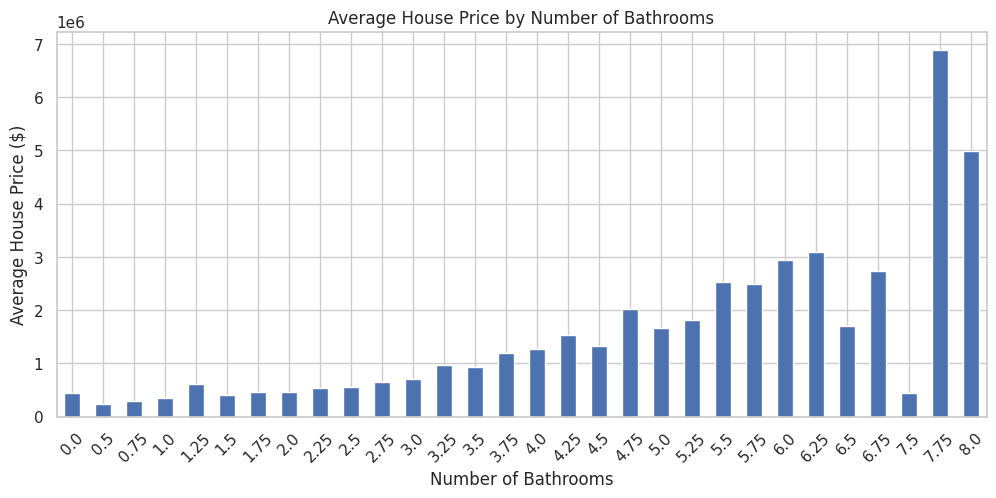

In [24]:
bathroom_prices = df.groupby('bathrooms')['price'].mean()

print("AVERAGE HOUSE PRICE BY NUMBER OF BATHROOMS")
print(bathroom_prices)

bathroom_prices.plot(
    kind='bar',
    figsize=(12, 5)
)

plt.title('Average House Price by Number of Bathrooms')
plt.xlabel('Number of Bathrooms')
plt.ylabel('Average House Price ($)')
plt.xticks(rotation=45)
plt.show()

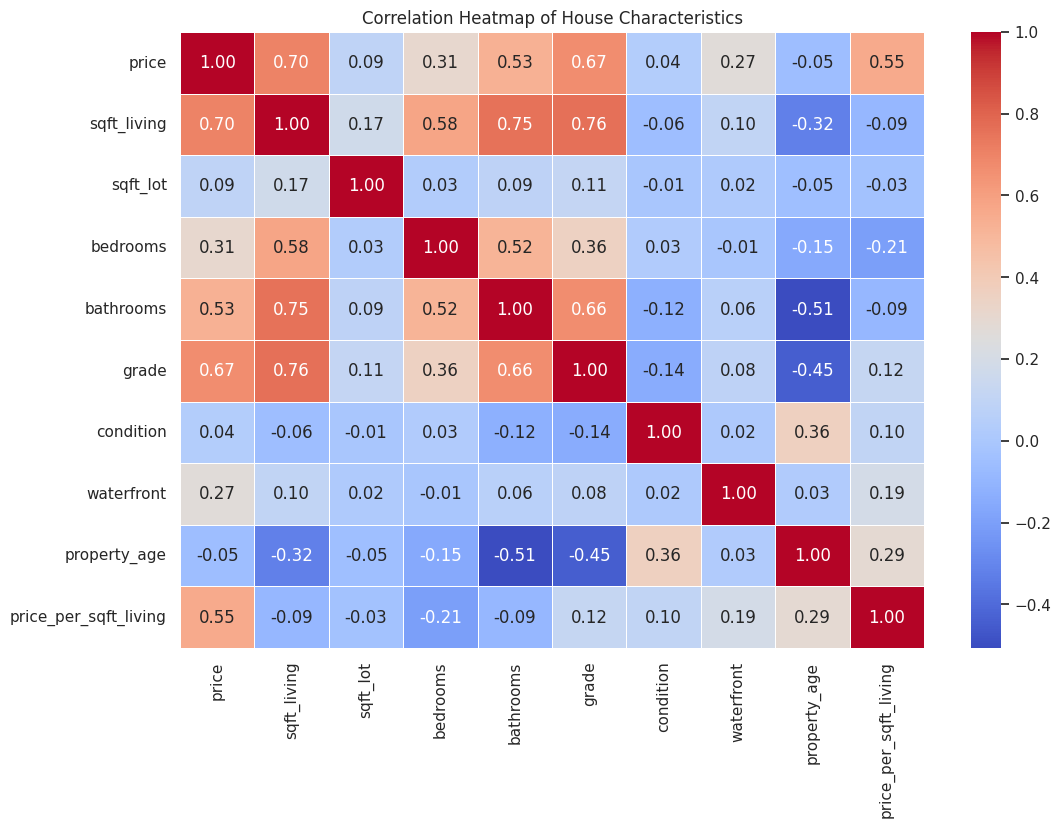

In [25]:
columns = [
    'price',
    'sqft_living',
    'sqft_lot',
    'bedrooms',
    'bathrooms',
    'grade',
    'condition',
    'waterfront',
    'property_age',
    'price_per_sqft_living'
]

correlation = df[columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of House Characteristics')
plt.show()

In [26]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

geo_data = df[['lat', 'long']].dropna().copy()

scaler = StandardScaler()

geo_scaled = scaler.fit_transform(
    geo_data[['lat', 'long']]
)

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

geo_data['cluster'] = kmeans.fit_predict(geo_scaled)

geo_data['price'] = df.loc[geo_data.index, 'price']
geo_data['grade'] = df.loc[geo_data.index, 'grade']
geo_data['sqft_living'] = df.loc[geo_data.index, 'sqft_living']
geo_data['waterfront'] = df.loc[geo_data.index, 'waterfront']

df.loc[geo_data.index, 'geo_cluster'] = geo_data['cluster']

print("GEOGRAPHIC CLUSTER COUNTS")
print(geo_data['cluster'].value_counts().sort_index())

GEOGRAPHIC CLUSTER COUNTS
cluster
0    4769
1    4666
2    6002
3    4209
4    1967
Name: count, dtype: int64


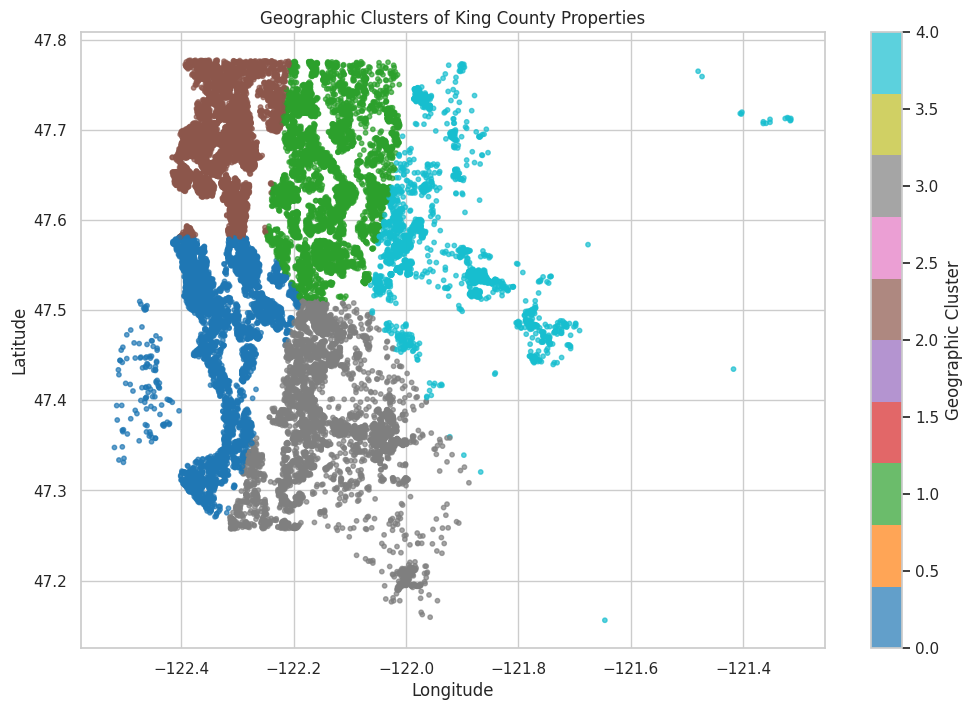

In [27]:
plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    geo_data['long'],
    geo_data['lat'],
    c=geo_data['cluster'],
    cmap='tab10',
    s=10,
    alpha=0.7
)

plt.colorbar(scatter, label='Geographic Cluster')

plt.title('Geographic Clusters of King County Properties')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

HOUSE PRICE ANALYSIS BY GEOGRAPHIC CLUSTER
         average_price  median_price  number_of_houses  average_grade  \
cluster                                                                 
1        758980.851907      640000.0              4666       8.304758   
4        577141.796645      536000.0              1967       8.113371   
2        619583.526491      525000.0              6002       7.557148   
0        394135.668484      329000.0              4769       7.173831   
3        332123.808506      308000.0              4209       7.414825   

         average_living_area  waterfront_houses  
cluster                                          
1                2531.582297                 47  
4                2474.216065                  0  
2                1890.883539                 30  
0                1779.897043                 86  
3                2004.351390                  0  


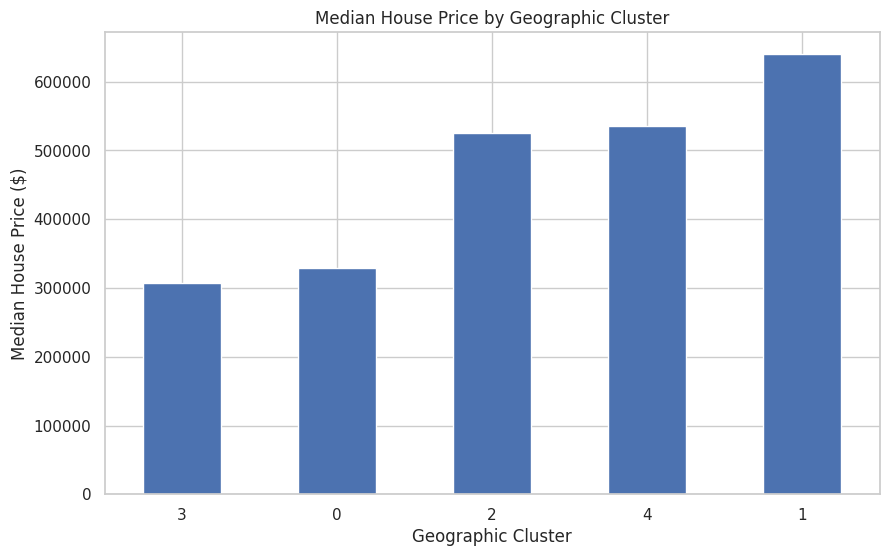

In [28]:
cluster_prices = geo_data.groupby('cluster').agg(
    average_price=('price', 'mean'),
    median_price=('price', 'median'),
    number_of_houses=('price', 'count'),
    average_grade=('grade', 'mean'),
    average_living_area=('sqft_living', 'mean'),
    waterfront_houses=('waterfront', 'sum')
)

print("HOUSE PRICE ANALYSIS BY GEOGRAPHIC CLUSTER")
print(cluster_prices.sort_values('median_price', ascending=False))

cluster_prices['median_price'].sort_values().plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Median House Price by Geographic Cluster')
plt.xlabel('Geographic Cluster')
plt.ylabel('Median House Price ($)')
plt.xticks(rotation=0)
plt.show()


In [29]:
print("GEOGRAPHIC CLUSTERS WITH HIGHER MEDIAN PRICES")

print(
    cluster_prices.sort_values(
        'median_price',
        ascending=False
    )
)

print("\nWATERFRONT PROPERTY COUNTS BY CLUSTER")

print(
    geo_data.groupby('cluster')['waterfront'].sum()
)

print("\nAVERAGE PROPERTY GRADE BY CLUSTER")

print(
    geo_data.groupby('cluster')['grade'].mean()
)

print("\nAVERAGE LIVING AREA BY CLUSTER")

print(
    geo_data.groupby('cluster')['sqft_living'].mean()
)


GEOGRAPHIC CLUSTERS WITH HIGHER MEDIAN PRICES
         average_price  median_price  number_of_houses  average_grade  \
cluster                                                                 
1        758980.851907      640000.0              4666       8.304758   
4        577141.796645      536000.0              1967       8.113371   
2        619583.526491      525000.0              6002       7.557148   
0        394135.668484      329000.0              4769       7.173831   
3        332123.808506      308000.0              4209       7.414825   

         average_living_area  waterfront_houses  
cluster                                          
1                2531.582297                 47  
4                2474.216065                  0  
2                1890.883539                 30  
0                1779.897043                 86  
3                2004.351390                  0  

WATERFRONT PROPERTY COUNTS BY CLUSTER
cluster
0    86
1    47
2    30
3     0
4     0
Name:

COMPARISON OF EXPENSIVE AND LESS EXPENSIVE ZIP CODES
                     Top 10 Expensive ZIP Codes  Bottom 10 ZIP Codes
median_price                      941788.350000        260020.200000
average_living_area                 2709.710494          1754.189444
average_grade                          8.626850             7.066485


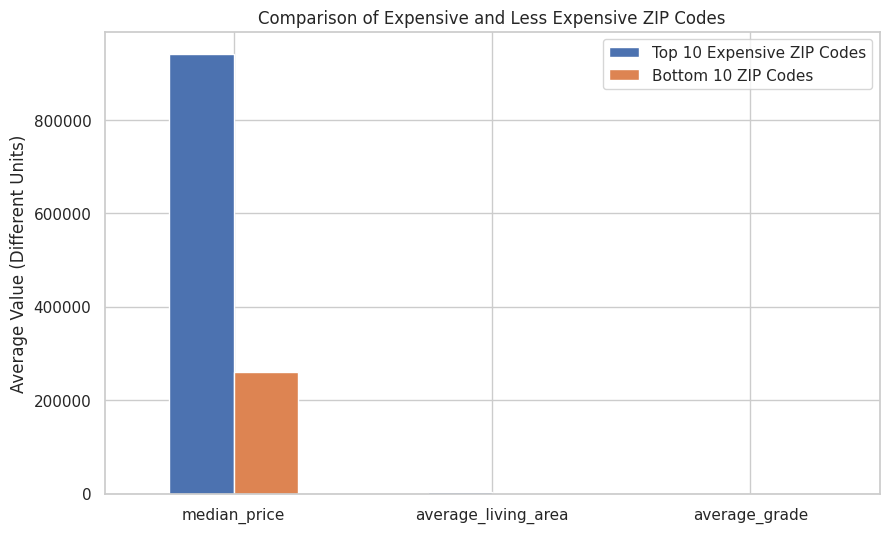

In [30]:
top10 = zipcode_prices.head(10)
bottom10 = zipcode_prices.tail(10)

comparison = pd.DataFrame({
    'Top 10 Expensive ZIP Codes': top10[
        ['median_price', 'average_living_area', 'average_grade']
    ].mean(),
    'Bottom 10 ZIP Codes': bottom10[
        ['median_price', 'average_living_area', 'average_grade']
    ].mean()
})

print("COMPARISON OF EXPENSIVE AND LESS EXPENSIVE ZIP CODES")
print(comparison)

comparison.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Comparison of Expensive and Less Expensive ZIP Codes')
plt.ylabel('Average Value (Different Units)')
plt.xticks(rotation=0)
plt.show()

In [31]:
print("REAL-ESTATE INVESTMENT SUMMARY REPORT")

print("\n1. OVERALL HOUSE PRICES")
print("Average Price: $", round(df['price'].mean(), 2))
print("Median Price: $", round(df['price'].median(), 2))

print("\n2. LIVING AREA")
print(
    "Correlation Between Living Area and Price:",
    round(df['sqft_living'].corr(df['price']), 3)
)

print("\n3. PROPERTY GRADE")
print(
    df.groupby('grade')['price']
    .median()
    .sort_values(ascending=False)
    .head()
)

print("\n4. PROPERTY CONDITION")
print(
    df.groupby('condition')['price']
    .median()
    .sort_values(ascending=False)
)

print("\n5. WATERFRONT")
print(
    df.groupby('waterfront')['price']
    .agg(['mean', 'median', 'count'])
)

print("\n6. RENOVATION")
print(
    df.groupby('is_renovated')['price']
    .agg(['mean', 'median', 'count'])
)

print("\n7. PROPERTY AGE")
print(
    "Correlation Between Property Age and Price:",
    round(df['property_age'].corr(df['price']), 3)
)

print("\n8. MOST EXPENSIVE ZIP CODES BY MEDIAN PRICE")
print(
    zipcode_prices[
        ['median_price', 'average_living_area', 'average_grade']
    ].head(10)
)

print("\n9. GEOGRAPHIC CLUSTERS BY MEDIAN PRICE")
print(
    cluster_prices.sort_values(
        'median_price',
        ascending=False
    )
)

REAL-ESTATE INVESTMENT SUMMARY REPORT

1. OVERALL HOUSE PRICES
Average Price: $ 540088.14
Median Price: $ 450000.0

2. LIVING AREA
Correlation Between Living Area and Price: 0.702

3. PROPERTY GRADE
grade
13    2983000.0
12    1817500.0
11    1284000.0
10     914327.0
9      720000.0
Name: price, dtype: float64

4. PROPERTY CONDITION
condition
5    526000.0
3    450000.0
4    440000.0
2    279000.0
1    262500.0
Name: price, dtype: float64

5. WATERFRONT
                    mean     median  count
waterfront                                
0           5.315636e+05   450000.0  21450
1           1.661876e+06  1400000.0    163

6. RENOVATION
                        mean    median  count
is_renovated                                 
Not Renovated  530360.818155  448000.0  20699
Renovated      760379.029540  600000.0    914

7. PROPERTY AGE
Correlation Between Property Age and Price: -0.054

8. MOST EXPENSIVE ZIP CODES BY MEDIAN PRICE
         median_price  average_living_area  average_grade

In [32]:
print("LIMITATIONS OF THE ANALYSIS")

print("1. House prices vary according to several property characteristics.")
print("2. Extreme property prices can affect averages and regression results.")
print("3. Geographic clusters depend on the selected number of clusters.")
print("4. ZIP codes may contain properties with different characteristics.")
print("5. The observed relationships do not prove cause and effect.")
print("6. The analysis does not include every factor affecting market value.")
print("7. Price per square foot uses different property sizes and lot areas.")
print("8. Investment decisions require further market and property-level research.")

LIMITATIONS OF THE ANALYSIS
1. House prices vary according to several property characteristics.
2. Extreme property prices can affect averages and regression results.
3. Geographic clusters depend on the selected number of clusters.
4. ZIP codes may contain properties with different characteristics.
5. The observed relationships do not prove cause and effect.
6. The analysis does not include every factor affecting market value.
7. Price per square foot uses different property sizes and lot areas.
8. Investment decisions require further market and property-level research.


In [33]:
print("INSIGHTS AND CONCLUSION")

print("\n1. LIVING AREA")
print(
    "Correlation between living area and price:",
    round(df['sqft_living'].corr(df['price']), 3)
)

print("\n2. PROPERTY GRADE")
print(
    "Median prices by grade:",
    df.groupby('grade')['price'].median().sort_values(ascending=False).head(5)
)

print("\n3. PROPERTY CONDITION")
print(
    "Median prices by condition:",
    df.groupby('condition')['price'].median().sort_values(ascending=False)
)

print("\n4. WATERFRONT STATUS")
print(
    "Average prices by waterfront status:",
    df.groupby('waterfront')['price'].mean()
)

print("\n5. RENOVATION STATUS")
print(
    "Average prices by renovation status:",
    df.groupby('is_renovated')['price'].mean()
)

print("\n6. PROPERTY AGE")
print(
    "Correlation between property age and price:",
    round(df['property_age'].corr(df['price']), 3)
)

print("\n7. GEOGRAPHIC PRICE PATTERNS")
print(
    "Highest median-price ZIP codes:",
    zipcode_prices['median_price'].head(5)
)

print("\n8. GEOGRAPHIC CLUSTERS")
print(
    cluster_prices['median_price'].sort_values(ascending=False)
)

print("\nCONCLUSION")
print(
    "Visual analytics helps compare house prices by living area, "
    "grade, condition, renovation status, waterfront access, and location."
)

print(
    "The results describe observed patterns in the dataset. "
    "Further analysis is needed before making property investment decisions."
)

INSIGHTS AND CONCLUSION

1. LIVING AREA
Correlation between living area and price: 0.702

2. PROPERTY GRADE
Median prices by grade: grade
13    2983000.0
12    1817500.0
11    1284000.0
10     914327.0
9      720000.0
Name: price, dtype: float64

3. PROPERTY CONDITION
Median prices by condition: condition
5    526000.0
3    450000.0
4    440000.0
2    279000.0
1    262500.0
Name: price, dtype: float64

4. WATERFRONT STATUS
Average prices by waterfront status: waterfront
0    5.315636e+05
1    1.661876e+06
Name: price, dtype: float64

5. RENOVATION STATUS
Average prices by renovation status: is_renovated
Not Renovated    530360.818155
Renovated        760379.029540
Name: price, dtype: float64

6. PROPERTY AGE
Correlation between property age and price: -0.054

7. GEOGRAPHIC PRICE PATTERNS
Highest median-price ZIP codes: zipcode
98039    1892500.0
98004    1150000.0
98040     993750.0
98112     915000.0
98005     765475.0
Name: median_price, dtype: float64

8. GEOGRAPHIC CLUSTERS
cluster

In [34]:
df.to_csv('Final Week-10.CSV',index=False)

print("WEEK 10 ANALYSIS DATASET SAVED SUCCESSFULLY")

WEEK 10 ANALYSIS DATASET SAVED SUCCESSFULLY
